# Quantum Many-Body Dynamics: Ising and PXP Models

Author: Tomás Caetano
Date: February 2026
Context: Engineering Physics Project

## Abstract
This notebook explores the non-equilibrium dynamics of interacting quantum many-body systems. We begin by implementing the time evolution of the Transverse Field Ising Model using the Suzuki-Trotter decomposition on a gate-based quantum circuit. Subsequently, we investigate the PXP model, a constrained Hamiltonian known for exhibiting weak ergodicity breaking and quantum many-body scars. The goal is to benchmark numerical exact diagonalization methods against Trotterized quantum simulation and analyze the fidelity of quantum states over time.

## 1. Theoretical Framework

The dynamics of a closed quantum system are governed by the time-dependent Schrodinger equation. For a time-independent Hamiltonian H, the state evolution is described by the unitary operator:

$$U(t) = e^{-iHt}$$

### Suzuki-Trotter Decomposition
In many-body systems, the Hamiltonian H is often a sum of non-commuting terms, such as H = A + B. Since the exponential of a sum is not the product of exponentials for non-commuting operators, we cannot implement U(t) directly as a sequence of elementary gates.

To approximate this evolution, we employ the first-order Suzuki-Trotter decomposition. For a total time t divided into M steps (where delta = t/M), the evolution operator is approximated as:

$$e^{-i(A+B)t} \approx \left( e^{-iA\delta} e^{-iB\delta} \right)^M + O(\delta^2)$$

This approximation becomes exact in the limit where M tends to infinity (or delta tends to zero). This allows us to simulate complex Hamiltonian dynamics using a sequence of simpler quantum gates.

### Models Under Study

#### 1. Transverse Field Ising Model (TFIM)
The TFIM describes a chain of spins with nearest-neighbor interactions subject to a transverse magnetic field. The Hamiltonian is given by:

$$H_{Ising} = -J \sum_{\langle i,j \rangle} Z_i Z_{j} - h \sum_{i} X_i$$

Here, J represents the interaction strength and h is the transverse field. This model exhibits a quantum phase transition between a ferromagnetic ordered phase and a paramagnetic disordered phase.

#### 2. PXP Model
The PXP model is an effective model for Rydberg atom arrays in the Rydberg blockade regime. It describes a chain of two-level systems where a spin flip (X operator) on site i is only allowed if its neighbors are in the ground state (projector P). The Hamiltonian is:

$$H_{PXP} = \sum_{i} P_{i-1} X_i P_{i+1}$$

where P = |0><0| is the projector onto the ground state. This model is significant for hosting quantum many-body scars, which are special eigenstates that violate the Eigenstate Thermalization Hypothesis (ETH) and allow for persistent oscillations from certain initial states (such as the Neel state).

In [2]:
import qiskit
import numpy as np
from qiskit import QuantumCircuit
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator

print("Qiskit imported successfully!")
print("Qiskit Version:", qiskit.__version__)

Qiskit imported successfully!
Qiskit Version: 2.1.2


In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import PauliEvolutionGate
import numpy as np
import matplotlib.pyplot as plt

# Example: U = exp(-i * dt * (X⊗Y⊗Z))
dt = np.pi/4
H = SparsePauliOp(["XYZ"], coeffs=[1.0])     # XYZ Hamiltonian
U = PauliEvolutionGate(H, time=dt)           # evolution gate

qc = QuantumCircuit(3)
qc.append(U, [0, 1, 2])
print(qc.draw())  # circuit diagram

     ┌────────────────────┐
q_0: ┤0                   ├
     │                    │
q_1: ┤1 exp(-it XYZ)(π/4) ├
     │                    │
q_2: ┤2                   ├
     └────────────────────┘


\begin{align*}
e^{\delta(A+B)} = e^{\delta A} \cdot e^{\delta B} + O(\delta^2)
\end{align*}
However, we know that $e^{\delta(A+B)} \neq e^{\delta A} \cdot e^{\delta B}$, as A and B are matrices that do not commute.
\\
If the Hamiltonian has a specific structure, we can compute $e^{-iHt}$ efficiently. This is where the Trotter decomposition comes in.
\\
Consider a Hamiltonian given by the following Ising model:
\begin{align*}
H = \sum_{i = 1}^{n-1}Z_i Z_{i+1}.
\end{align*}
We can decompose the Hamiltonian as follows:
\begin{align*}
e^{-iHt} = e^{-i \left( \sum_{i=1}^{n-1} Z_i Z_{i+1} \right)t}
= \left( e^{-i (Z_1 Z_2 + Z_2 Z_3 + \cdots) \frac{t}{M}} \right)^M
\approx \left( e^{-i (Z_1 Z_2) \frac{t}{M}} \cdot e^{-i (Z_2 Z_3) \frac{t}{M}} \cdots \right)^M
\end{align*}
We effectively have a small matrix (2-qubit gates, 4 dimensions). In other words, the action of an exponentially large matrix can be written as a polynomial product of matrices (2-qubit gates).

# Implementation of quantum dynamics (1): Ising model

Let us consider the following spin model:
\begin{align*}
H = J\sum_{i = 1}^{n -1}Z_iZ_{i+1}
\end{align*}
$J$ is the parameter defining the spin interaction strength. $J > 0$ favors anti-aligned spins (negative energy), and for $J < 0$ the opposite occurs.
\\
To apply a phase to the spin pairs (different if even or odd), we implement a quantum circuit with a $CNOT$ on the second qubit (which measures the parity of the spins). Then, we apply an $R_z$ gate, applying a negative phase of $\pi/2$ to spin pairs with odd parity and a positive phase of $\pi/2$ to spin pairs with even parity. Finally, another $CNOT$ is applied to retrieve the original state with the phases applied.
\\
\\

- Objective:
$$
e^{-i\delta\, Z_i Z_{i+1}}
$$

- Initial state:
$$
|\psi\rangle = a|00\rangle + b|01\rangle + c|10\rangle + d|11\rangle
$$

- 1) CNOT_{i \to i+1}:
$$
|\psi\rangle \mapsto
a|00\rangle + b|01\rangle + c|11\rangle + d|10\rangle
$$

- 2) Apply R_z(2\delta) on qubit (i{+}1):
$$
|0\rangle \to e^{-i\delta}|0\rangle, \qquad
|1\rangle \to e^{+i\delta}|1\rangle
$$
$$
a e^{-i\delta}|00\rangle +
b e^{-i\delta}|01\rangle +
c e^{+i\delta}|11\rangle +
d e^{+i\delta}|10\rangle
$$

- 3) Apply CNOT_{i \to i+1} again (uncompute):
$$
\boxed{
e^{-i\delta}(a|00\rangle + d|11\rangle)
+
e^{+i\delta}(b|01\rangle + c|10\rangle)
}
$$
Equivalent to:
$$
e^{-i\delta Z_i Z_{i+1}}|\psi\rangle
$$

- Numerical example:
$$
\delta=\frac{\pi}{6},\qquad a=b=c=d=\tfrac12
$$
$$
|\psi_{\rm out}\rangle
=
\tfrac12\big(
e^{-i\pi/6}|00\rangle
+ e^{+i\pi/6}|01\rangle
+ e^{+i\pi/6}|10\rangle
+ e^{-i\pi/6}|11\rangle
\big)
$$

The observable we want to evaluate is the expectation value of the Magnetization given by:
\begin{align*}
M = \frac{1}{6} \sum_{i = 1}^{6}Z_i
\end{align*}
If we were to execute the circuit, we would verify that this value is constant, because the Ising Model only interacts in the $z$ direction, and the magnetization in $z$ is conserved, since:
\begin{align*}
Z\ket{0} = \ket{0}
\\
Z\ket{1} = -\ket{1}
\end{align*}
$Z$ is diagonal, meaning it will not alter the measured values (it may apply a global phase, but that is irrelevant). In short, $Z$ acts like a ruler.

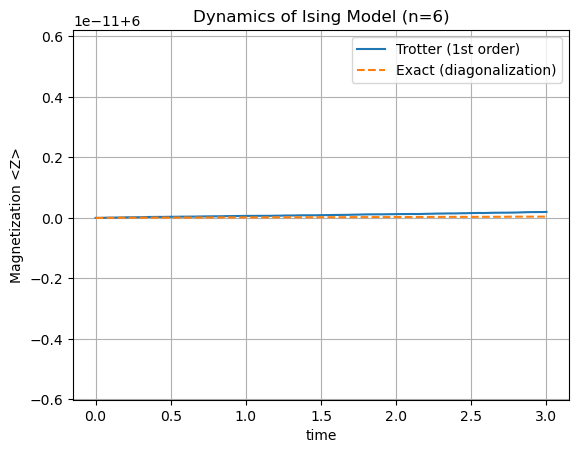

In [12]:
nqubits = 6
t_total = 3.0
M = 100
delta = t_total / M
h = 0.0
ring = True

def neighbors(n, ring=True):
    pairs = [(i, (i+1) % n) for i in range(n)]
    return pairs if ring else pairs[:-1]

def total_magnetization_op(n):
    
    paulis = []
    coeffs = []
    for i in range(n):
        s = ["I"]*n
        s[i] = "Z"
        paulis.append("".join(s))
        coeffs.append(1.0)
    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=complex))

def tfim_hamiltonian(n, h, ring=True):
    paulis = []
    coeffs = []
    # ZZ couplings
    for (i,j) in neighbors(n, ring):
        s = ["I"]*n
        s[i] = "Z"; s[j] = "Z"
        paulis.append("".join(s))
        coeffs.append(1.0)
    # X fields
    for i in range(n):
        s = ["I"]*n
        s[i] = "X"
        paulis.append("".join(s))
        coeffs.append(h)
    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=complex))

def trotter_step_circuit(n, delta, h, ring=True):
    qc = QuantumCircuit(n, name="trotter_step")
    # ZZ
    for (i,j) in neighbors(n, ring):
        qc.cx(i, j)
        qc.rz(2*delta, j) 
        qc.cx(i, j)
    # X field
    for i in range(n):
        qc.rx(2*h*delta, i) 
    return qc

# Trotter Simulation
def simulate_trotter(n, delta, M, h, measure_op):
    sv = Statevector.from_label("0"*n)
    vals = [ sv.expectation_value(measure_op).real ]
    step = trotter_step_circuit(n, delta, h, ring=True)
    for _ in range(M):
        sv = sv.evolve(step)
        vals.append( sv.expectation_value(measure_op).real )
    return vals
    
# Diagonalization (Exact)
def exact_step_operator(n, delta, h, ring=True):
    H = tfim_hamiltonian(n, h, ring=ring).to_matrix()  # 2^n x 2^n
    evals, evecs = np.linalg.eigh(H)
    phases = np.exp(-1j * delta * evals)
    U = (evecs @ np.diag(phases) @ evecs.conj().T)
    return Operator(U)

def simulate_exact(n, delta, M, h, measure_op):
    sv = Statevector.from_label("0"*n)
    U = exact_step_operator(n, delta, h, ring=True)
    vals = [ sv.expectation_value(measure_op).real ]
    for _ in range(M):
        sv = sv.evolve(U)
        vals.append( sv.expectation_value(measure_op).real )
    return vals

mag_op = total_magnetization_op(nqubits)
y_trotter = simulate_trotter(nqubits, delta, M, h, mag_op)
y_exact   = simulate_exact  (nqubits, delta, M, h, mag_op)
times = [k*delta for k in range(M+1)]

plt.figure()
plt.plot(times, y_trotter, label="Trotter (1st order)")
plt.plot(times, y_exact,   label="Exact (diagonalization)", linestyle="--")
plt.xlabel("time")
plt.ylabel("Magnetization <Z>")
plt.title("Dynamics of Ising Model (n=6)")
plt.legend()
plt.grid()
plt.show()

# Implementation of Quantum Dynamics: Transverse Magnetic Field Ising Model

Let us consider the following Hamiltonian:
\begin{align*}
H = \sum_{i = 1}^{n}Z_iZ_{i+1} + h\sum_{i = 1}^{n}X_i
\end{align*}
$h$ here represents a coefficient of the transverse magnetic field strength, and $X_i$ is the Pauli operator representing the magnetization of the i-th particle in the $x$ direction.
\\
When performing the Trotter decomposition, we will add the term:
\begin{align*}
e^{-ihX_1 \frac{t}{M}} ... e^{-ihX_n \frac{t}{M}}
\end{align*}
to the previous Ising model.

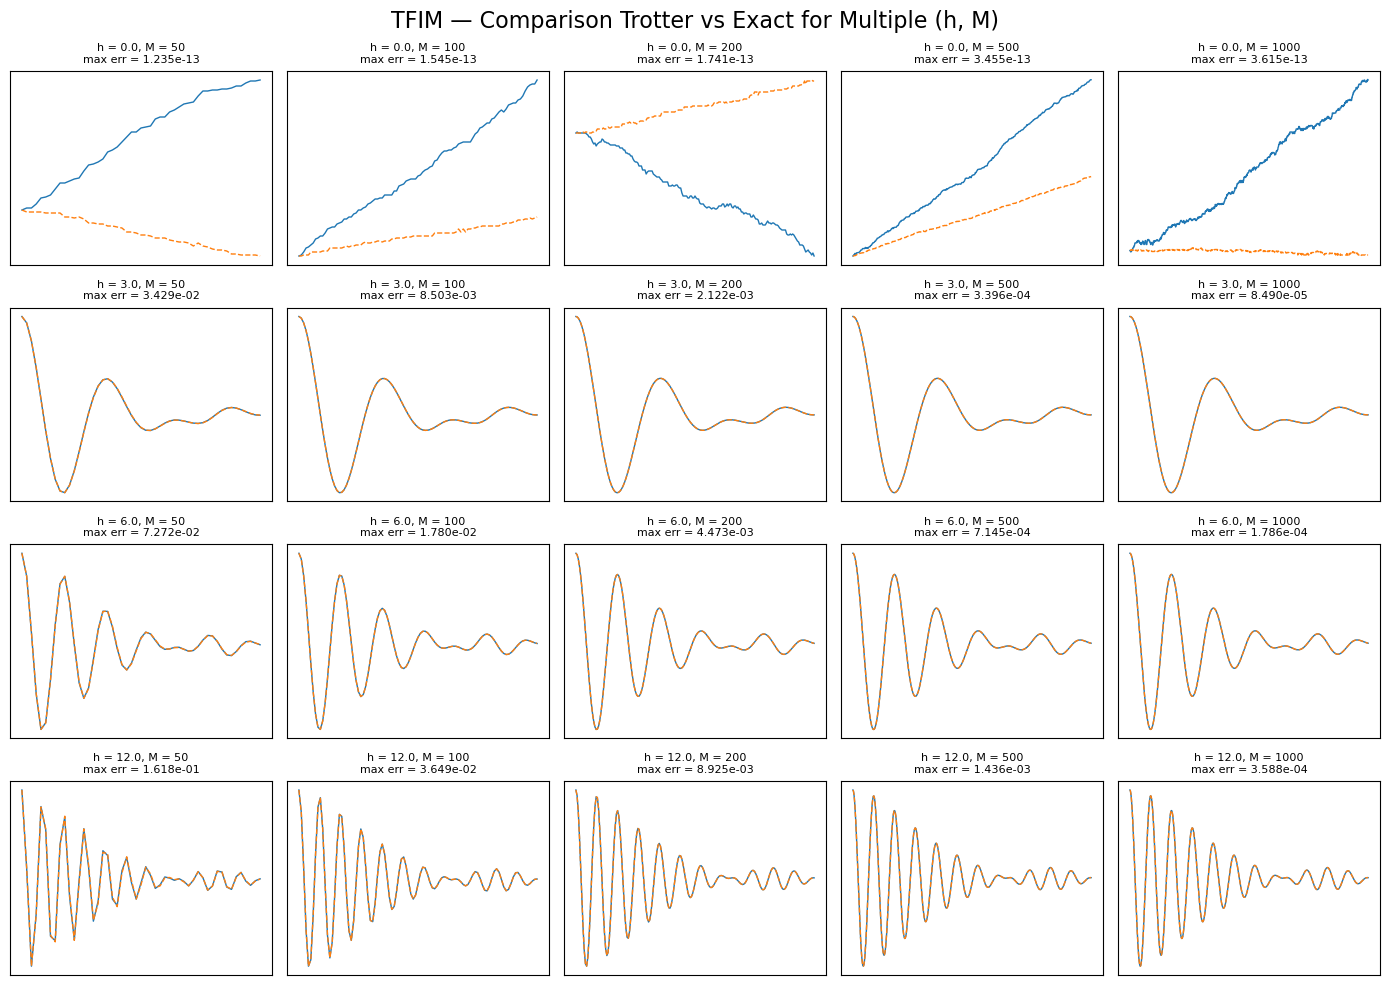

In [9]:
nqubits = 6          
t_total = 3.0         
M = 100              
h = 3.0               
ring = True          


def neighbors(n, ring=True):
    pairs = [(i, (i+1) % n) for i in range(n)]
    return pairs if ring else pairs[:-1]

def total_magnetization_op(n):
    """Observable Sum_i Z_i como SparsePauliOp."""
    paulis = []
    coeffs = []
    for i in range(n):
        s = ["I"]*n
        s[i] = "Z"
        paulis.append("".join(s))
        coeffs.append(1.0)
    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=complex))

def tfim_hamiltonian(n, h, ring=True):
    paulis = []
    coeffs = []
    # ZZ couplings
    for (i,j) in neighbors(n, ring):
        s = ["I"]*n
        s[i] = "Z"; s[j] = "Z"
        paulis.append("".join(s))
        coeffs.append(1.0)
    # X fields
    for i in range(n):
        s = ["I"]*n
        s[i] = "X"
        paulis.append("".join(s))
        coeffs.append(h)
    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=complex))


# Trotter
def trotter_step_circuit(n, delta, h, ring=True):
    qc = QuantumCircuit(n, name="trotter_step")
    # ZZ
    for (i,j) in neighbors(n, ring):
        qc.cx(i, j)
        qc.rz(2*delta, j)    # exp(-i (2*delta)/2 Z) = exp(-i delta Z)
        qc.cx(i, j)
    # X field
    for i in range(n):
        qc.rx(2*h*delta, i)  # exp(-i (2*h*delta)/2 X) = exp(-i h*delta X)
    return qc

def simulate_trotter(n, delta, M, h, measure_op):
    sv = Statevector.from_label("0"*n)
    vals = [sv.expectation_value(measure_op).real]
    step = trotter_step_circuit(n, delta, h, ring=True)
    for _ in range(M):
        sv = sv.evolve(step)
        vals.append(sv.expectation_value(measure_op).real)
    return vals


# Diagonalização
def exact_step_operator(n, delta, h, ring=True):
    H = tfim_hamiltonian(n, h, ring=ring).to_matrix()  # 2^n x 2^n
    evals, evecs = np.linalg.eigh(H)
    phases = np.exp(-1j * delta * evals)
    U = (evecs @ np.diag(phases) @ evecs.conj().T)
    return Operator(U)

def simulate_exact(n, delta, M, h, measure_op):
    sv = Statevector.from_label("0"*n)
    U = exact_step_operator(n, delta, h, ring=True)
    vals = [sv.expectation_value(measure_op).real]
    for _ in range(M):
        sv = sv.evolve(U)
        vals.append(sv.expectation_value(measure_op).real)
    return vals


# correr tudo
def run_tfim(n, t_total, M, h):
    delta = t_total / M
    mag_op = total_magnetization_op(n)
    y_trotter = simulate_trotter(n, delta, M, h, mag_op)
    y_exact   = simulate_exact  (n, delta, M, h, mag_op)
    times = np.linspace(0, t_total, M+1)
    err_series = np.abs(np.array(y_trotter) - np.array(y_exact))
    err_max = err_series.max()
    return times, y_trotter, y_exact, err_series, err_max


hs = [0.0, 3.0, 6.0, 12.0]
Ms = [50, 100, 200, 500, 1000]

plt.figure(figsize=(14, 10))

plot_index = 1
for h_val in hs:
    for M_val in Ms:
        times, yT, yE, err_series, err_max = run_tfim(nqubits, t_total, M_val, h_val)

        plt.subplot(len(hs), len(Ms), plot_index)
        plt.plot(times, yT, label="Trotter", linewidth=1)
        plt.plot(times, yE, label="Exact", linestyle="--", linewidth=1)
        plt.title(f"h = {h_val}, M = {M_val}\nmax err = {err_max:.3e}", fontsize=8)
        plt.xticks([], [])
        plt.yticks([], [])
        plot_index += 1

plt.suptitle("TFIM — Comparison Trotter vs Exact for Multiple (h, M)", fontsize=16)
plt.tight_layout()
plt.show()


The following observations were made based on the simulation results:

1) Increasing the transverse field strength $h$ results in larger oscillations in the system's magnetization values.

2) For a fixed value of $h$, the magnetization curve becomes smoother as the number of Trotter steps $M$ increases. This is consistent with theoretical expectations: a larger number of steps implies a smaller time step ($\delta = t/M$), resulting in higher simulation accuracy.

3) We also verify the expected error scaling associated with the first-order Trotter decomposition:
\begin{align*}
    e^{\delta (A+B)} = e^{\delta A}\, e^{\delta B} + O(\delta^2).
\end{align*}
Since $\delta = t/M$, increasing the number of steps by a factor of 10 is expected to reduce the error by a factor of approximately $100$. This quadratic convergence behavior is effectively observed in our numerical results.


## Theoretical Overview of the PXP Model

The PXP model serves as a theoretical representation of a chain of Rydberg atoms—atoms maintained in highly excited states. In this model, interactions between neighboring atoms give rise to unique physical behaviors.

To simulate this system, we approximate the time evolution using first-order Trotterization, analogous to the approach taken for the Ising model. We construct a quantum circuit to approximate the time evolution operator:

$$U(t) = e^{-iH_{PXP}t}$$

The Hamiltonian is given by:

$$H_{\text{PXP}} = \Omega \sum_{i=1}^{n-2} P_{i-1} X_i P_{i+1}, \quad P = |0\rangle\!\langle 0| = \frac{I+Z}{2}$$

This Hamiltonian implements the Rydberg blockade mechanism:
* Each qubit represents a neutral atom in either the ground state $|0\rangle$ or the excited state $|1\rangle$.
* The operator $X_i$ performs a flip between these states.
* The projectors $P_{i-1}$ and $P_{i+1}$ ensure that an atom can only be excited if its two nearest neighbors are in the ground state $|0\rangle$.

We can expand the projector $P$ in terms of Pauli operators, given that $P = (I+Z)/2$:

$$P_{i-1} X_i P_{i+1} = \frac{1}{4} \left( X_i + Z_{i-1}X_i + X_i Z_{i+1} + Z_{i-1}X_i Z_{i+1} \right)$$

Consequently, the Hamiltonian becomes a sum of Pauli strings $P_k$:

$$H_{\text{PXP}} = \sum_k h_k P_k$$

This decomposition facilitates the implementation of each term using standard quantum gates for Pauli evolution.

### Understanding the Projector

A projector is an operator that verifies a specific condition and preserves only the component of the state that satisfies it. Intuitively, one might visualize the projector as posing a question to the qubit: "Are you in state $|0\rangle$?"

* If yes, the state is preserved as is.
* If no, the component is annihilated (mapped to 0).

This is why it is termed a projector; it projects the vector onto the subspace where the condition holds true. We can define this formally using the completeness relation:

$$P = |0\rangle\langle 0| = \begin{pmatrix} 1 & 0 \\ 0 & 0 \end{pmatrix}$$

Which implies:

$$P|0\rangle = |0\rangle$$
$$P|1\rangle = 0$$

Verifying the equality $P = (I + Z)/2$:

$$I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}, \quad Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$

$$\frac{I + Z}{2} = \frac{1}{2} \begin{pmatrix} 2 & 0 \\ 0 & 0 \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 0 \end{pmatrix}$$

Expressing the projector in terms of Pauli matrices is ideal for two reasons: it allows us to implement these operators in a quantum circuit, and it facilitates the expansion of the Hamiltonian into a SparsePauliOp for Trotterization. Without this decomposition, implementing $P$ directly as a quantum gate would be non-trivial.

To recapitulate, this projector allows atom $i$ to flip between $|0\rangle$ and $|1\rangle$ only if its two neighbors are in $|0\rangle$. This represents the Rydberg blockade, with the projectors serving as the mechanism for this constraint.

### The Néel State and Quantum Many-Body Scars

For this project, we initialize the system in the Néel state, which takes the form:

$$|10101010...\rangle$$

This state consists of an alternating pattern of excitations that fully respects the PXP constraint. The Néel state is significant because it lies close to a rare dynamical subspace where:
* The Hamiltonian nearly closes upon itself.
* The state oscillates between similar patterns.
* The system returns almost to its initial state after a certain time (revivals).
* The fidelity periodically approaches unity.

This phenomenon is known as Quantum Many-Body Scars. Much like a stable orbit within a chaotic system, the Néel state represents a privileged trajectory of the PXP Hamiltonian.

### Mechanism of Revivals

The question arises: how and why do these revivals occur in the Néel state? Let us consider an intuitive example for 4 qubits in the state $|1010\rangle$:

$$q_0 \quad q_1 \quad q_2 \quad q_3$$

In this example, qubits $q_0$ and $q_2$ are excited, while their neighbors are in the ground state, satisfying the Rydberg blockade. Upon applying the PXP Hamiltonian term $P_{i-1}X_iP_{i+1}$ to each qubit $i$:

For qubit 0: $X_0 P_{q_1}$. Since $q_1 = 0$, the condition is satisfied, and the qubit can flip. Possible result: $|0010\rangle$.

For qubit 1: $P_{q_0} X_1 P_{q_2}$. Since $q_0 = 1$ and $q_2 = 1$, the condition is not satisfied. The qubit is blocked.

For qubit 2: $P_{q_1} X_2 P_{q_3}$. Since $q_1 = 0$ and $q_3 = 0$, the condition is satisfied, and the qubit can flip. Possible result: $|1000\rangle$.

For qubit 3: $P_{q_2} X_3$. Since $q_2 = 1$, the condition is not satisfied. The qubit is blocked.

The action of the Hamiltonian maps the state as follows:
$$|1010\rangle \rightarrow |0010\rangle, \quad |1000\rangle$$

While a 4-qubit system has $2^4 = 16$ possible combinations, applying the PXP Hamiltonian to the Néel state restricts access to only a few specific states.

If we apply the Hamiltonian again to the state $|0010\rangle$:
* $q_0$ can flip $\rightarrow |1010\rangle$.
* $q_1$ is blocked (by $q_2=1$).
* $q_2$ can flip $\rightarrow |0000\rangle$.
* $q_3$ is blocked.

The possible transitions for $|0010\rangle$ are back to $|1010\rangle$ or to $|0000\rangle$. Repeating the process for the other branch ($|1000\rangle$) confirms that it also connects back to $|1010\rangle$ and a limited number of other allowed states.

In other words, the system dynamics remain trapped in a very small subspace rather than exploring the full 16-dimensional Hilbert space.

$$|1010\rangle \leftrightarrow |0010\rangle, \quad |1000\rangle \leftrightarrow \text{few other states}$$

The projector rules prevent the majority of the 16 states from participating in the evolution. Since the dynamics only traverse a small circular route of states, the system eventually returns almost to the initial state after a time $T$, with fidelity:

$$F(T) = |\langle 1010 | \psi(T) \rangle|^2 \approx 1$$

This is what we call a revival. While not mathematically perfect, the fidelity is close to 1 and the pattern repeats periodically. These quasi-periodic trajectories are the "scars." In a typical thermalizing many-body quantum system, internal coherence would be lost, and the system would spread across the Hilbert space, never returning to the initial configuration.

Applying Trotterization to simulate the time evolution operator, we obtain:

\begin{align*}
e^{-i H \Delta t} 
\;\approx\; 
\prod_k e^{-i h_k P_k \,\delta} + O(\delta^2)
\end{align*}

where

\begin{align*}
\delta = \frac{t}{M}
\end{align*}

To implement this, the following steps are required:
* Retrieve the list of terms ($h_k P_k$) from the Hamiltonian in SparsePauliOp format.
* Construct the Trotterization sequence as previously demonstrated.
* Apply the circuit $M$ times to the initial Neel state.
* Calculate the fidelity of the state over time.
* Calculate the total magnetization.
* Compare the exact evolution (via diagonalization) against the Trotterized simulation to observe: the quality of the approximation, the shift in revival peaks, and the accumulated error over time.

Initial Neel State: |10101010> (visual convention)


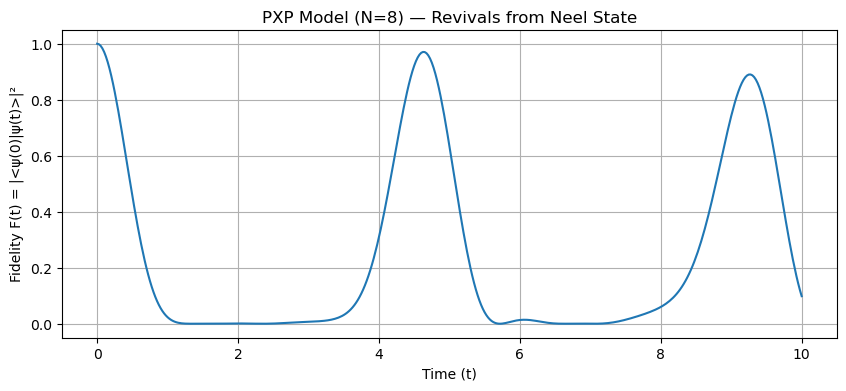

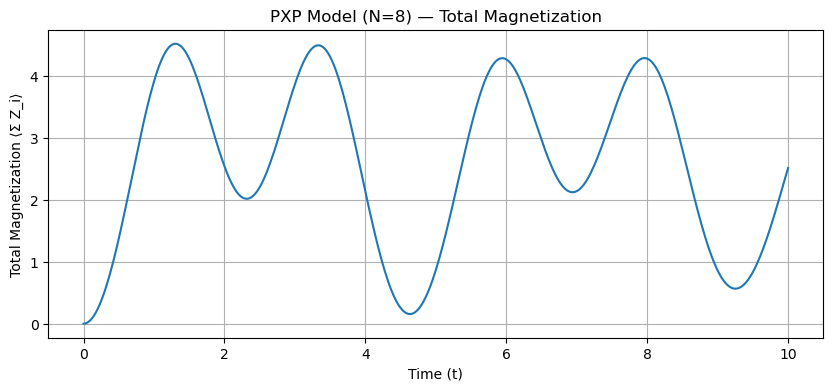

In [10]:
# PXP Hamiltonian Construction
def pxp_hamiltonian(n, Omega=1.0):
    
    paulis = []
    coeffs = []

    # Only middle qubits have two neighbors (Open Boundary Conditions)
    for i in range(1, n-1):  
        # Expand P_{i-1} X_i P_{i+1} = (1/4)*(X_i + Z_{i-1}X_i + X_i Z_{i+1} + Z_{i-1}X_i Z_{i+1})
        for leftZ in [0, 1]:
            for rightZ in [0, 1]:
                s = ["I"] * n
                s[i] = "X"
                
                # Construct Pauli string based on expansion terms
                if leftZ:
                    s[i-1] = "Z"
                if rightZ:
                    s[i+1] = "Z"
                
                paulis.append("".join(s))
                coeffs.append(Omega * 0.25)

    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=complex))


def exact_step_operator_from_sparse(H_sparse, delta):
    """
    Constructs U = exp(-i H delta) from a SparsePauliOp H 
    via exact diagonalization (similar to the Ising model approach).
    """
    H = H_sparse.to_matrix()
    evals, evecs = np.linalg.eigh(H)
    phases = np.exp(-1j * delta * evals)
    U = evecs @ np.diag(phases) @ evecs.conj().T
    return Operator(U)


def neel_state(n):
    """
    Creates the Statevector for the Neel state |1010...> (starting with |1> at qubit 0).
    """
    # Generate bitstring "1010..." of length n
    bs = "".join("1" if i % 2 == 0 else "0" for i in range(n))
    # Qiskit convention - reverse the string for Little Endian representation
    return Statevector.from_label(bs[::-1]), bs


def simulate_pxp_exact(n, t_total, M, Omega=1.0):
    """
    Exact time evolution of the PXP model starting from the Neel state:
      - n: number of qubits
      - t_total: total simulation time
      - M: number of time steps (delta = t_total / M)
    Returns:
      times, fidelities, magnetizations, bitstring_label
    """
    delta = t_total / M
    H_pxp = pxp_hamiltonian(n, Omega)
    U = exact_step_operator_from_sparse(H_pxp, delta)

    psi0, bitstring = neel_state(n)
    psi = psi0.copy()

    # Assuming 'total_magnetization_op' was defined in previous cells
    mag_op = total_magnetization_op(n)

    times = [0.0]
    fidelities = [1.0]  # F(0) = 1
    magnetizations = [psi.expectation_value(mag_op).real]

    for k in range(1, M+1):
        psi = psi.evolve(U)
        times.append(k * delta)
        
        # Calculate fidelity with respect to the initial state
        F = abs(np.vdot(psi0.data, psi.data))**2
        fidelities.append(F)
        magnetizations.append(psi.expectation_value(mag_op).real)

    return times, fidelities, magnetizations, bitstring


# Simulation Parameters
n_pxp    = 8        
t_total  = 10.0      
M        = 400       
Omega    = 1.0       

# Run Simulation
times, F_t, M_t, neel_bs = simulate_pxp_exact(n_pxp, t_total, M, Omega)

print(f"Initial Neel State: |{neel_bs}> (visual convention)")

# Plot 1: Fidelity
plt.figure(figsize=(10,4))
plt.plot(times, F_t)
plt.xlabel("Time (t)")
plt.ylabel("Fidelity F(t) = |<ψ(0)|ψ(t)>|²")
plt.title(f"PXP Model (N={n_pxp}) — Revivals from Neel State")
plt.grid(True)
plt.show()

# Plot 2: Magnetization
plt.figure(figsize=(10,4))
plt.plot(times, M_t)
plt.xlabel("Time (t)")
plt.ylabel("Total Magnetization ⟨Σ Z_i⟩")
plt.title(f"PXP Model (N={n_pxp}) — Total Magnetization")
plt.grid(True)
plt.show()

The first plot indicates the presence of quantum revivals around $t \approx 4$ and $t \approx 9$. This signifies that the system returns close to the initially prepared Néel state, as evidenced by the fidelity measurements approaching unity ($\approx 1$).

The second plot displays the time evolution of the total magnetization. We observe that the system starts with zero net magnetization ($M=0$), which is consistent with the symmetric nature of the Néel state (containing an equal number of excited $|1\rangle$ and ground $|0\rangle$ states). The total magnetization subsequently exhibits an oscillatory behavior over time.

Notably, this oscillation remains predominantly positive, indicating a higher population of ground states $|0\rangle$ compared to excited states $|1\rangle$. This behavior is a direct consequence of the kinetic constraints imposed by the projectors (Rydberg blockade), which energetically forbid adjacent excitations, thereby limiting the maximum density of $|1\rangle$ states.

We further observe a correlation between the two observables: when the total magnetization returns to values near zero, a corresponding peak appears in the fidelity plot. This confirms that the return to a zero-magnetization configuration corresponds to the system revisiting the initial Néel state.

Initial Neel state (n=4): |1010>


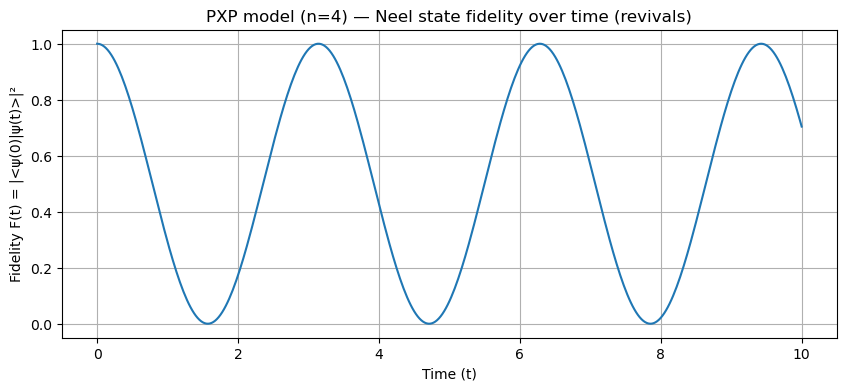

In [11]:
n_pxp   = 4
t_total = 10.0
M       = 400
Omega   = 1.0

# Run exact simulation for N=4
times_4, F_4, M_4, neel_bs_4 = simulate_pxp_exact(n_pxp, t_total, M, Omega)

print(f"Initial Neel state (n=4): |{neel_bs_4}>")

plt.figure(figsize=(10,4))
plt.plot(times_4, F_4)
plt.xlabel("Time (t)")
plt.ylabel("Fidelity F(t) = |<ψ(0)|ψ(t)>|²")
plt.title("PXP model (n=4) — Neel state fidelity over time (revivals)")
plt.grid(True)
plt.show()

## Conclusion: Quantum Scars in the PXP Model

In this study, we investigated the non-equilibrium dynamics of the PXP model, a constrained Hamiltonian describing Rydberg atom arrays in the blockade regime. By simulating the time evolution of the system initialized in the Neel state, we observed distinct periodic revivals in the state fidelity and magnetization.

These results confirm the presence of Quantum Many-Body Scars. Unlike typical chaotic quantum systems that thermalize rapidly according to the Eigenstate Thermalization Hypothesis (ETH), the PXP model exhibits weak ergodicity breaking. The kinetic constraints imposed by the Rydberg blockade isolate specific trajectories in the Hilbert space, preventing the system from exploring the full state space and forcing it to revisit its initial configuration.

Furthermore, we validated the digital quantum simulation approach by benchmarking the first-order Trotterization against exact diagonalization. The Trotterized evolution successfully captured the oscillation frequency of the revivals. However, we observed a gradual decay in fidelity over time compared to the exact result, which is consistent with the accumulation of algorithmic errors inherent to the discretization of the time evolution operator.